In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from tensorflow import keras
from tensorflow.keras import layers

In [5]:
data = pd.read_csv("NASA Turbofan ENgine/NASA TurboFan Engine.csv")

print(data.head())
print(data.shape)
print(data.columns)

   unit  cycle  setting1  setting2  setting3  sensor1  sensor2  sensor3  \
0     1      1   -0.0007   -0.0004     100.0   518.67   641.82  1589.70   
1     1      2    0.0019   -0.0003     100.0   518.67   642.15  1591.82   
2     1      3   -0.0043    0.0003     100.0   518.67   642.35  1587.99   
3     1      4    0.0007    0.0000     100.0   518.67   642.35  1582.79   
4     1      5   -0.0019   -0.0002     100.0   518.67   642.37  1582.85   

   sensor4  sensor5  ...  sensor14  sensor15  sensor16  sensor17  sensor18  \
0  1400.60    14.62  ...   8138.62    8.4195      0.03       392      2388   
1  1403.14    14.62  ...   8131.49    8.4318      0.03       392      2388   
2  1404.20    14.62  ...   8133.23    8.4178      0.03       390      2388   
3  1401.87    14.62  ...   8133.83    8.3682      0.03       392      2388   
4  1406.22    14.62  ...   8133.80    8.4294      0.03       393      2388   

   sensor19  sensor20  sensor21  RUL  Fault_Label  
0     100.0     39.06   23.4

In [6]:
sensor_columns = ['sensor' + str(i) for i in range(1, 22)]

X = data[sensor_columns]
y = data['Fault_Label']

scaler = MinMaxScaler()
X = scaler.fit_transform(X)

print("Data shape:", X.shape)

Data shape: (20631, 21)


In [7]:
healthy_data = X[y == 0]

X_train = []

for i in range(len(healthy_data) - 9):
    X_train.append(healthy_data[i:i+10])

X_train = np.array(X_train)

print("Training shape:", X_train.shape)

Training shape: (17522, 10, 21)


In [8]:
model = keras.Sequential([
    layers.Input(shape=(10, 21)),
    layers.LSTM(32),
    layers.RepeatVector(10),
    layers.LSTM(32, return_sequences=True),
    layers.TimeDistributed(layers.Dense(21))
])

model.compile(optimizer='adam', loss='mse')

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 32)                  │           6,912 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ repeat_vector (RepeatVector)         │ (None, 10, 32)              │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm_1 (LSTM)                        │ (None, 10, 32)              │           8,320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ time_distributed (TimeDistributed)   │ (None, 10, 21)              │             693 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 15,925 (62.21 KB)

 Trainable params: 15,925 (62.21 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
history = model.fit(
    X_train, X_train,
    epochs=10,
    batch_size=32
)

Epoch 1/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 13s 12ms/step - loss: 0.0100
Epoch 2/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0043
Epoch 3/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0042
Epoch 4/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0042
Epoch 5/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0041
Epoch 6/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 9s 17ms/step - loss: 0.0041
Epoch 7/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 8s 14ms/step - loss: 0.0040
Epoch 8/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.0038
Epoch 9/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 13ms/step - loss: 0.0038
Epoch 10/10
548/548 ━━━━━━━━━━━━━━━━━━━━ 7s 12ms/step - loss: 0.0037


In [10]:
predictions = model.predict(X_train)

error = np.mean((X_train - predictions) ** 2, axis=(1, 2))

threshold = np.percentile(error, 95)

print("Threshold:", threshold)

548/548 ━━━━━━━━━━━━━━━━━━━━ 4s 7ms/step
Threshold: 0.008521004780158787


In [11]:
X_test = []

for i in range(len(X) - 9):
    X_test.append(X[i:i+10])

X_test = np.array(X_test)

predictions = model.predict(X_test)

test_error = np.mean((X_test - predictions) ** 2, axis=(1, 2))

fault_predictions = (test_error > threshold).astype(int)

print("Predicted Faults:", fault_predictions)

645/645 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step
Predicted Faults: [0 0 0 ... 0 0 0]


In [12]:
from sklearn.metrics import accuracy_score, classification_report

actual = y.values[9:]

print("Accuracy:", accuracy_score(actual, fault_predictions))
print(classification_report(actual, fault_predictions))

Accuracy: 0.7809620793327514
              precision    recall  f1-score   support

           0       0.84      0.92      0.88     17522
           1       0.04      0.02      0.03      3100

    accuracy                           0.78     20622
   macro avg       0.44      0.47      0.45     20622
weighted avg       0.72      0.78      0.75     20622



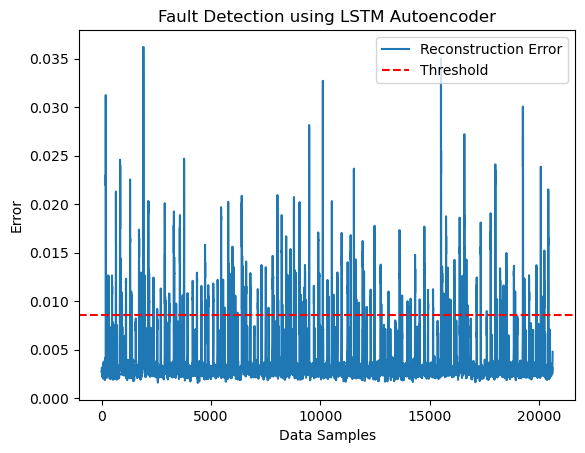

In [13]:
plt.plot(test_error, label='Reconstruction Error')
plt.axhline(threshold, color='red', linestyle='--', label='Threshold')

plt.xlabel('Data Samples')
plt.ylabel('Error')
plt.title('Fault Detection using LSTM Autoencoder')
plt.legend()
plt.show()